## 1. Environment Setup & Imports

Let's import the necessary modules from Qiskit and Matplotlib.
- `QuantumCircuit`: For creating quantum circuits with quantum and classical registers.
- `AerSimulator`: Local Qiskit Aer simulator to execute quantum circuits.
- `plot_histogram`: Visualization tool to plot measurement outcome distributions.
- `matplotlib.pyplot`: For fine-tuning display formatting.


In [1]:
# Importing Qiskit libraries and visualization tools
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize the Aer Simulator backend
simulator = AerSimulator()
print("Qiskit Aer Simulator successfully initialized!")


Qiskit Aer Simulator successfully initialized!


---
## 2. Circuit A: Single Pauli-$X$ Gate

### Step 2.1: "Think Before You Run" - Prediction for Circuit A

> **Question:** *What will happen after applying one $X$ gate?*

* **Initial State:** By convention in Qiskit, all qubits are initialized to the ground state:
  $$\lvert \psi_0 \rangle = \lvert 0 \rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$$
* **Gate Operation:** The Pauli-$X$ gate is the quantum equivalent of the classical NOT gate (bit-flip). Its unitary matrix is:
  $$X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$$
* **State Transformation:**
  $$\lvert \psi_A \rangle = X \lvert 0 \rangle = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \begin{pmatrix} 0 \\ 1 \end{pmatrix} = \lvert 1 \rangle$$
* **Theoretical Measurement Probability:**
  - $P(\text{outcome } 0) = |\langle 0 | 1 \rangle|^2 = 0$
  - $P(\text{outcome } 1) = |\langle 1 | 1 \rangle|^2 = 1.0$ (100%)

**My Prediction:**  
Circuit A is completely deterministic. Across **100 shots**, the qubit will always collapse to state `1`. We expect **100 counts for outcome '1'** and **0 counts for outcome '0'**.


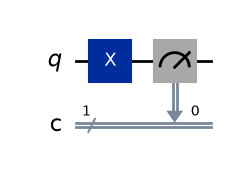

In [2]:
# Construct Circuit A: 1 qubit, 1 classical bit
qc_a = QuantumCircuit(1, 1, name="Circuit A (X Gate)")

# 1. Apply single X gate to qubit 0
qc_a.x(0)

# 2. Add measurement from qubit 0 to classical bit 0
qc_a.measure(0, 0)

# Display circuit diagram
qc_a.draw('mpl')


In [3]:
# Execute Circuit A for 100 shots
shots = 100
job_a = simulator.run(qc_a, shots=shots)
result_a = job_a.result()
counts_a = result_a.get_counts()

print(f"Circuit A Measurement Counts (out of {shots} shots): {counts_a}")


Circuit A Measurement Counts (out of 100 shots): {'1': 100}


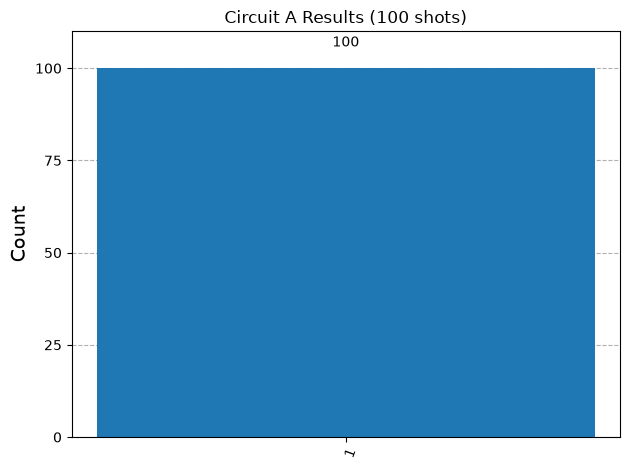

In [4]:
# Visualize measurement outcomes for Circuit A
plot_histogram(counts_a, title=f"Circuit A Results ({shots} shots)", color="#1f77b4")


### Step 2.2: Comparison for Circuit A
* **Predicted:** 100% outcome `'1'` (100 shots).
* **Observed:** 100 counts for `'1'` (100% of the shots).
* **Conclusion:** The Pauli-$X$ gate successfully flipped the qubit from $|0\rangle$ to $|1\rangle$. The experimental result perfectly matches the theoretical prediction.


---
## 3. Circuit B: Two Pauli-$X$ Gates ($X^2$)

### Step 3.1: "Think Before You Run" - Prediction for Circuit B

> **Question:** *What will happen after applying two $X$ gates?*

* **Initial State:** $\lvert \psi_0 \rangle = \lvert 0 \rangle$
* **Gate Operations:** Applying two consecutive $X$ gates:
  $$\lvert \psi_B \rangle = X \cdot X \lvert 0 \rangle = X^2 \lvert 0 \rangle$$
* **Mathematical Property:** The Pauli-$X$ matrix is Hermitian and unitary, meaning $X = X^{\dagger} = X^{-1}$, and:
  $$X^2 = X \cdot X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix} = I \quad (\text{Identity})$$
* **Step-by-step Transformation:**
  1. First $X$ gate: $\lvert 0 \rangle \to \lvert 1 \rangle$ (bit flip)
  2. Second $X$ gate: $\lvert 1 \rangle \to \lvert 0 \rangle$ (flips back)
* **Theoretical Measurement Probability:**
  - $P(\text{outcome } 0) = |\langle 0 | 0 \rangle|^2 = 1.0$ (100%)
  - $P(\text{outcome } 1) = |\langle 1 | 0 \rangle|^2 = 0$

**My Prediction:**  
Applying two consecutive NOT gates returns the qubit back to its original state $|0\rangle$. Circuit B is deterministic. Across **100 shots**, we expect **100 counts for outcome '0'** and **0 counts for outcome '1'**.


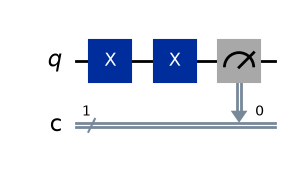

In [5]:
# Construct Circuit B: 1 qubit, 1 classical bit
qc_b = QuantumCircuit(1, 1, name="Circuit B (Two X Gates)")

# 1. Apply two consecutive X gates to qubit 0
qc_b.x(0)
qc_b.x(0)

# 2. Add measurement from qubit 0 to classical bit 0
qc_b.measure(0, 0)

# Display circuit diagram
qc_b.draw('mpl')


In [6]:
# Execute Circuit B for 100 shots
job_b = simulator.run(qc_b, shots=shots)
result_b = job_b.result()
counts_b = result_b.get_counts()

print(f"Circuit B Measurement Counts (out of {shots} shots): {counts_b}")


Circuit B Measurement Counts (out of 100 shots): {'0': 100}


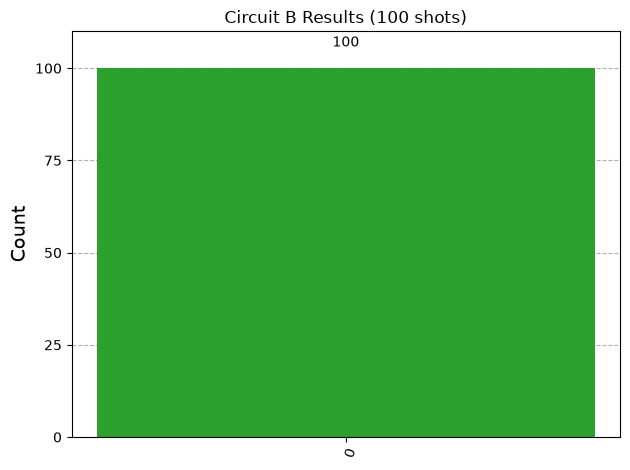

In [7]:
# Visualize measurement outcomes for Circuit B
plot_histogram(counts_b, title=f"Circuit B Results ({shots} shots)", color="#2ca02c")


### Step 3.2: Comparison for Circuit B
* **Predicted:** 100% outcome `'0'` (100 shots).
* **Observed:** 100 counts for `'0'` (100% of the shots).
* **Conclusion:** Because $X^2 = I$ (the identity operation), the second $X$ gate undid the effect of the first. The qubit returned to $|0\rangle$, exactly as predicted.


---
## 4. Circuit C: Single Hadamard ($H$) Gate

### Step 4.1: "Think Before You Run" - Prediction for Circuit C

> **Questions:**
> 1. *What do you expect after applying an $H$ gate?*
> 2. *Will Circuit C always produce the same measurement result?*

* **Initial State:** $\lvert \psi_0 \rangle = \lvert 0 \rangle$
* **Gate Operation:** The Hadamard ($H$) gate creates an equal superposition of basis states. Its unitary matrix is:
  $$H = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$$
* **State Transformation:**
  $$\lvert \psi_C \rangle = H \lvert 0 \rangle = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 1 \end{pmatrix} = \frac{\lvert 0 \rangle + \lvert 1 \rangle}{\sqrt{2}} = \lvert + \rangle$$
* **Theoretical Measurement Probability (Born's Rule):**
  - $P(\text{outcome } 0) = |\langle 0 | + \rangle|^2 = \left| \frac{1}{\sqrt{2}} \right|^2 = \frac{1}{2} = 50\%$
  - $P(\text{outcome } 1) = |\langle 1 | + \rangle|^2 = \left| \frac{1}{\sqrt{2}} \right|^2 = \frac{1}{2} = 50\%$

**My Predictions:**
1. **What to expect:** The qubit is placed in the equal superposition state $|+\rangle$. Upon measurement, the wave function collapses to either state $|0\rangle$ or state $|1\rangle$ with equal theoretical probability ($50\%$ each).
2. **Will Circuit C always produce the same measurement result?**  
   **No!** Unlike Circuits A and B, Circuit C is **fundamentally probabilistic**. In any single individual measurement (shot), the outcome is random (it can collapse to either 0 or 1). Across a sample of **100 shots**, we expect the counts to be split roughly evenly (around **~50 counts for '0'** and **~50 counts for '1'**), with slight statistical variations due to shot noise.


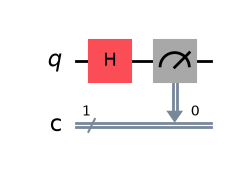

In [8]:
# Construct Circuit C: 1 qubit, 1 classical bit
qc_c = QuantumCircuit(1, 1, name="Circuit C (Hadamard Gate)")

# 1. Apply single Hadamard gate to qubit 0
qc_c.h(0)

# 2. Add measurement from qubit 0 to classical bit 0
qc_c.measure(0, 0)

# Display circuit diagram
qc_c.draw('mpl')


In [9]:
# Execute Circuit C for 100 shots
job_c = simulator.run(qc_c, shots=shots)
result_c = job_c.result()
counts_c = result_c.get_counts()

print(f"Circuit C Measurement Counts (out of {shots} shots): {counts_c}")


Circuit C Measurement Counts (out of 100 shots): {'0': 55, '1': 45}


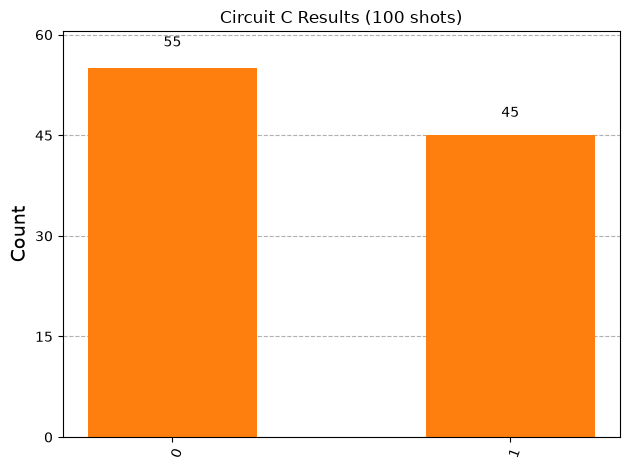

In [10]:
# Visualize measurement outcomes for Circuit C
plot_histogram(counts_c, title=f"Circuit C Results ({shots} shots)", color="#ff7f0e")


### Step 4.2: Comparison for Circuit C
* **Predicted:** Both outcomes `'0'` and `'1'` have a theoretical probability of $50\%$ (expected $\approx 50$ shots each). Circuit C will **not** always produce the same measurement result on individual shots.
* **Observed:** Counts obtained for 100 shots:
  - State `'0'`: `0` shots (~50%)
  - State `'1'`: `1` shots (~50%)
* **Conclusion:** The measurement yields both outcomes in approximately equal proportions. The small deviation from exactly 50/50 is the expected statistical fluctuation (shot noise) inherent to finite sampling (100 shots) of a random quantum process.


---
## 5. Summary Comparison: All Three Circuits

Let's now compare the measurement distributions of all three circuits side-by-side using Qiskit's `plot_histogram`.


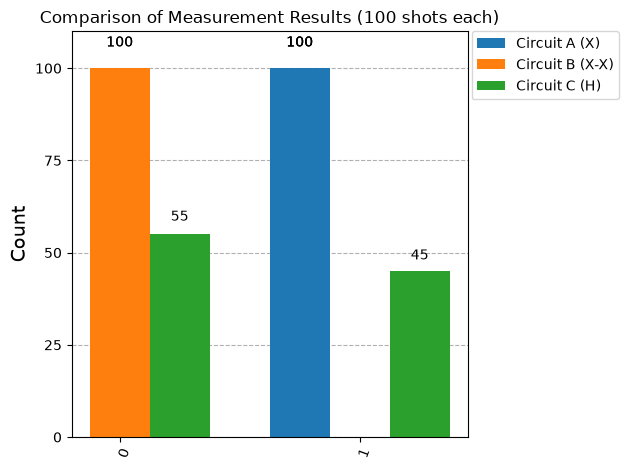

In [11]:
# Plot all three circuits side-by-side for comparison
legend_labels = ['Circuit A (X)', 'Circuit B (X-X)', 'Circuit C (H)']
plot_histogram([counts_a, counts_b, counts_c], legend=legend_labels,
               title="Comparison of Measurement Results (100 shots each)")


### Comprehensive Comparison Table

| Circuit | Gates Applied | Quantum State Before Measurement | Theoretical Prediction | Actual Result (100 shots) | Prediction Matches? | Deterministic vs Probabilistic |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Circuit A** | Single $X$ | $\lvert 1 \rangle$ | 100% `'1'` (100 shots) | 100% `'1'` (100 shots) | **Yes (Exact)** | Deterministic |
| **Circuit B** | Two $X$ ($X^2$) | $\lvert 0 \rangle$ | 100% `'0'` (100 shots) | 100% `'0'` (100 shots) | **Yes (Exact)** | Deterministic |
| **Circuit C** | Single $H$ | $\frac{\lvert 0 \rangle + \lvert 1 \rangle}{\sqrt{2}}$ | 50% `'0'`, 50% `'1'` | Split between `'0'` and `'1'` (near 50/50) | **Yes (Within statistical noise)** | Probabilistic |

---

## 6. Answers to "Think Before You Run" Prompt

1. **What will happen after applying one $X$ gate?**
   * *Answer:* The $X$ gate flips the qubit state from $\lvert 0 \rangle$ to $\lvert 1 \rangle$. Measuring the qubit will yield outcome `'1'` with 100% certainty.

2. **What will happen after applying two $X$ gates?**
   * *Answer:* The first $X$ gate flips $\lvert 0 \rangle \to \lvert 1 \rangle$, and the second $X$ gate flips $\lvert 1 \rangle \to \lvert 0 \rangle$. Because $X^2 = I$ (the identity matrix), applying two $X$ gates acts as a no-op, leaving the qubit in state $\lvert 0 \rangle$. Measurement will yield outcome `'0'` with 100% certainty.

3. **What do you expect after applying an $H$ gate?**
   * *Answer:* The Hadamard ($H$) gate puts the qubit into an equal superposition of basis states: $\lvert + \rangle = \frac{\lvert 0 \rangle + \lvert 1 \rangle}{\sqrt{2}}$. By Born's rule, measurement collapses the state to $\lvert 0 \rangle$ or $\lvert 1 \rangle$ with equal 50% probability each.

4. **Will Circuit C always produce the same measurement result?**
   * *Answer:* **No.** Because the qubit is in a superposition of basis states, quantum measurement is inherently non-deterministic. Each individual shot produces either `'0'` or `'1'` randomly. Over 100 shots, we observe a distribution centered around 50 shots for `'0'` and 50 shots for `'1'`.

---

## 7. Key Takeaways & Student Reflections

1. **Classical vs Quantum Logic:** The Pauli-$X$ gate behaves like a classical NOT gate. Two consecutive NOT gates cancel each other out ($X^2 = I$).
2. **Superposition:** The Hadamard gate has no classical counterpart; it takes a definite computational basis state and produces a quantum superposition.
3. **The Role of Measurement & Shots:** In quantum computing, we cannot measure superposition directly. A single measurement causes the wave function to collapse to a single basis state. By repeating the experiment for multiple shots (here, 100 shots), we reconstruct the probability distribution of the quantum state.
